### Chapter 3 — Coding Attention Mechanisms: Giáo trình học chi tiết  
- Attention Mechanism (Cơ chế tập trung) là một kỹ thuật mang tính cách mạng trong học máy và trí tuệ nhân tạo (đặc biệt là trong Xử lý ngôn ngữ tự nhiên - NLP và Thị giác máy tính).
#### 1.1 Tại sao xử lý chuỗi dài lại khó?
Trong NLP, dữ liệu văn bản có tính tuần tự. Ý nghĩa của một token không chỉ phụ thuộc vào chính nó mà còn phụ thuộc vào các token xung quanh.  
Ví dụ:
The animal didn't cross the street because it was too tired.
  
Để hiểu từ "it", mô hình phải xác định mối liên hệ với "the animal" thay vì "the street".  
Nếu chỉ xem từng từ riêng lẻ, mô hình không thể xác định được mối quan hệ này một cách đáng tin cậy.  

#### 1.2. Encoder–Decoder RNN
- Trước Transformer, một phương pháp phổ biến để dịch máy là kiến trúc encoder-decoder sử dụng RNN.  
  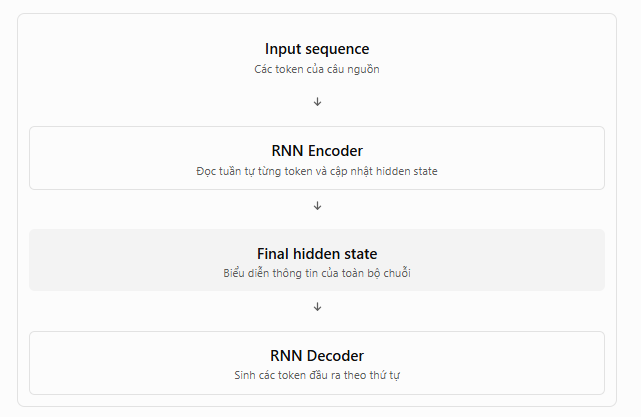  
  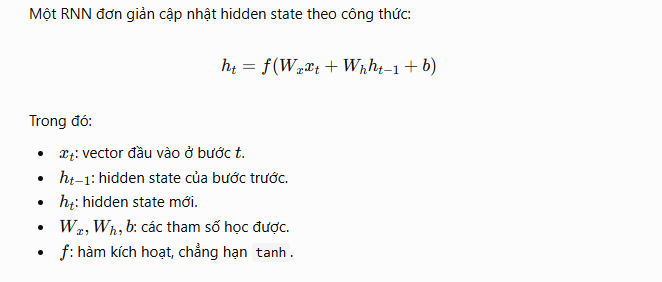  

#### 1.3. Hạn chế của RNN encoder-decoder  
- Trong mô hình encoder-decoder RNN cơ bản được sách trình bày, toàn bộ câu nguồn phải được nén vào final hidden state.
- Với câu dài, đây có thể trở thành information bottleneck — nút thắt thông tin.
  - Ngoài ra, RNN xử lý các bước thời gian theo thứ tự, nên khó song song hóa theo chiều chuỗi.

### Section 3.2: Capturing Data Dependencies with Attention Mechanisms
#### 2.1. Attention là gì?
- Attention là cơ chế tính toán mức độ liên quan giữa các phần tử và sử dụng các mức độ đó để kết hợp thông tin.
- Ví dụ câu: Your journey starts with one step.
    - Khi xử lý token "journey", mô hình có thể kết hợp thông tin từ "Your", "starts", "with", "one" và "step".
    - Tuy nhiên, mỗi token không nhất thiết đóng góp như nhau.
  - => có 2 loại attention
    - Attention giữa 2 chuỗi : liên kết giữa 2 chuỗi khác nhau, vd decoder chú ý đến encoder => hữu ích cho việc dịch máy 
    - Self-attention: các thành phần nằm trong 1 câu với nhau => token chú ý đến các token khác trong 1 câu, là thành phần cốt lõi của GPT( gểnative pre-traing tranformer)
#### 2.3. Contextual representation
Trong Chapter 2, bạn đã học embedding:
$$
\text{Token ID}\rightarrow\text{Embedding vector}
$$

Embedding đầu vào cung cấp một biểu diễn vector cho token.
Sang Chapter 3:
$$
\text{Input embedding}\rightarrow\text{Self-Attention}\rightarrow\text{Context vector}
$$

Context vector là biểu diễn đã được bổ sung thông tin từ các token khác.
Ví dụ từ "bank" trong hai câu:
  - I deposited money at the bank.
  - We sat near the river bank.
  - Mô hình có thể tạo ra hai context vectors khác nhau cho "bank" nhờ ngữ cảnh khác nhau.  
- Đây là lý do contextual representations hữu ích hơn việc chỉ sử dụng embedding cố định.  
**Điều cần nhớ: Self-Attention không trực tiếp dự đoán token tiếp theo. Nó tạo ra các biểu diễn có ngữ cảnh, sau đó được những thành phần khác của GPT sử dụng.**

### Phần 3 — Section 3.3: Attending to Different Parts of the Input with Self-Attention
- 3.3.1. Input embeddings
Sách sử dụng câu:
Your journey starts with one step.

Gồm 6 token, mỗi token có embedding 3 chiều
